In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.ticker import AutoMinorLocator

C:\Users\Sophie.Kaye\Anaconda3\lib\site-packages\scipy\__init__.py:138: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.24.4)
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion} is required for this version of "


In [2]:
myworkingdirectory = r"C:\Users\Sophie.Kaye\Desktop\NPS Crash Data"
os.chdir(myworkingdirectory)

In [3]:
analysis_2024 = pd.read_csv("./analysis_database_2024.csv")

<ipython-input-3-60bb7cbbd6e1>:1: DtypeWarning: Columns (68) have mixed types. Specify dtype option on import or set low_memory=False.
  analysis_2024 = pd.read_csv("./analysis_database_2024.csv")


In [4]:
analysis_2024.shape

(218593, 71)

In [5]:
analysis_2024.head()

,INCID_NO,5_mph,10_mph,15_mph,20_mph,25_mph,30_mph,35_mph,40_mph,45_mph,...,LONGITUDE,Park,RGN,YEAR,MONTH,DOW,HOUR,TIME,Urban,database
0,ABLI070425075000,0,0,0,0,0,0,0,0,0,...,NaN,ABLI,SER,2007.0,4,3,7,750.0,rural,CDS
1,ABLI070804175500,1,0,0,0,0,0,0,0,0,...,NaN,ABLI,SER,2007.0,8,6,17,1755.0,rural,CDS
2,ABLI091117170900,0,0,0,0,1,0,0,0,0,...,NaN,ABLI,SER,2009.0,11,2,17,1709.0,rural,CDS
3,ABLI121009110000,0,0,0,0,1,0,0,0,0,...,NaN,ABLI,SER,2012.0,10,2,11,1100.0,rural,CDS
4,ABLI140610163500,0,0,0,0,0,0,0,0,0,...,-76.93412,ABLI,SER,2014.0,6,2,16,1635.0,rural,CDS


In [6]:
analysis_2024.columns

Index(['INCID_NO', '5_mph', '10_mph', '15_mph', '20_mph', '25_mph', '30_mph',
       '35_mph', '40_mph', '45_mph', '50_mph', '55_mph', '60_mph', '65_mph',
       '70_mph', '75_mph', 'no_posted_speed', 'Crosswalk',
       'Outside a Crosswalk', 'NUM_VEH', 'Num_Motorcycle', 'Pax', 'SUV', 'Van',
       'Bus', 'Medium Truck', 'Heavy Truck', 'Equipment', 'Nonroad HighSpeed',
       'Nonroad LowSpeed', 'Unknown', 'Motorcycle_Ind', 'No Injury',
       'Possible Injury', 'Non-incapacitating Injury', 'Incapacitating Injury',
       'Fatality', 'Num_Motorist', 'Num_Non_Motorist', 'Num_Pedestrian',
       'Num_Ped_Deaths', 'Pedestrian', 'VRU', 'Crash_Severity',
       'CrashSeverity_Fatal', 'CrashSeverity_Incap', 'CrashSeverity_NonIncap',
       'CrashSeverity_Possible', 'CrashSeverity_NoInj', 'First_Harmful_Event',
       'First_Harmful_Event_Type', 'Involving Animal', 'Daylight', 'Dawn',
       'Dusk', 'Dark_Lit', 'Dark_NotLit', 'Dark_UnknownLit',
       'UnknownBlankNullLit', 'Poor Lighting', 

# 2D Heatmap Plotting

## Percentage of Fatalities

In [12]:
# 2D heatmap - requires numpy array of just Z values from  3D plot, see example here: https://datavizpyr.com/heatmap-with-matplotlib-in-python/
# query fatality values for each hour, to become columns of array (months are already in order, so rows of array are all set)

allfatals = analysis_2024[['HOUR','MONTH','Fatality']]
allfatals_agg = allfatals.groupby(['MONTH','HOUR']).sum().reset_index()
midnight_allfatals = allfatals_agg['Fatality'].loc[allfatals_agg['HOUR']==0.0]
one_allfatals = allfatals_agg['Fatality'].loc[allfatals_agg['HOUR']==1.0]
two_allfatals = allfatals_agg['Fatality'].loc[allfatals_agg['HOUR']==2.0]
three_allfatals = allfatals_agg['Fatality'].loc[allfatals_agg['HOUR']==3.0]
four_allfatals = allfatals_agg['Fatality'].loc[allfatals_agg['HOUR']==4.0]
five_allfatals = allfatals_agg['Fatality'].loc[allfatals_agg['HOUR']==5.0]
six_allfatals = allfatals_agg['Fatality'].loc[allfatals_agg['HOUR']==6.0]
seven_allfatals = allfatals_agg['Fatality'].loc[allfatals_agg['HOUR']==7.0]
eight_allfatals = allfatals_agg['Fatality'].loc[allfatals_agg['HOUR']==8.0]
nine_allfatals = allfatals_agg['Fatality'].loc[allfatals_agg['HOUR']==9.0]
ten_allfatals = allfatals_agg['Fatality'].loc[allfatals_agg['HOUR']==10.0]
eleven_allfatals = allfatals_agg['Fatality'].loc[allfatals_agg['HOUR']==11.0]
twelve_allfatals = allfatals_agg['Fatality'].loc[allfatals_agg['HOUR']==12.0]
thirteen_allfatals = allfatals_agg['Fatality'].loc[allfatals_agg['HOUR']==13.0]
fourteen_allfatals = allfatals_agg['Fatality'].loc[allfatals_agg['HOUR']==14.0]
fifteen_allfatals = allfatals_agg['Fatality'].loc[allfatals_agg['HOUR']==15.0]
sixteen_allfatals = allfatals_agg['Fatality'].loc[allfatals_agg['HOUR']==16.0]
seventeen_allfatals = allfatals_agg['Fatality'].loc[allfatals_agg['HOUR']==17.0]
eighteen_allfatals = allfatals_agg['Fatality'].loc[allfatals_agg['HOUR']==18.0]
nineteen_allfatals = allfatals_agg['Fatality'].loc[allfatals_agg['HOUR']==19.0]
twenty_allfatals = allfatals_agg['Fatality'].loc[allfatals_agg['HOUR']==20.0]
twentyone_allfatals = allfatals_agg['Fatality'].loc[allfatals_agg['HOUR']==21.0]
twentytwo_allfatals = allfatals_agg['Fatality'].loc[allfatals_agg['HOUR']==22.0]
twentythree_allfatals = allfatals_agg['Fatality'].loc[allfatals_agg['HOUR']==23.0]

# combine columns into wide array
allfatals_array = pd.DataFrame(np.column_stack([midnight_allfatals,one_allfatals,two_allfatals,three_allfatals,four_allfatals,five_allfatals,six_allfatals,seven_allfatals,eight_allfatals,nine_allfatals,ten_allfatals,eleven_allfatals,twelve_allfatals,thirteen_allfatals,fourteen_allfatals,fifteen_allfatals,sixteen_allfatals,seventeen_allfatals,eighteen_allfatals,nineteen_allfatals,twenty_allfatals,twentyone_allfatals,twentytwo_allfatals,twentythree_allfatals]), columns=['midnight_allfatals','one_allfatals','two_allfatals','three_allfatals','four_allfatals','five_allfatals','six_allfatals','seven_allfatals','eight_allfatals','nine_allfatals','ten_allfatals','eleven_allfatals','twelve_allfatals','thirteen_allfatals','fourteen_allfatals','fifteen_allfatals','sixteen_allfatals','seventeen_allfatals','eighteen_allfatals','nineteen_allfatals','twenty_allfatals','twentyone_allfatals','twentytwo_allfatals','twentythree_allfatals'])
allfatals_array.head()

,midnight_allfatals,one_allfatals,two_allfatals,three_allfatals,four_allfatals,five_allfatals,six_allfatals,seven_allfatals,eight_allfatals,nine_allfatals,...,fourteen_allfatals,fifteen_allfatals,sixteen_allfatals,seventeen_allfatals,eighteen_allfatals,nineteen_allfatals,twenty_allfatals,twentyone_allfatals,twentytwo_allfatals,twentythree_allfatals
0,1.0,7.0,8.0,2.0,2.0,2.0,3.0,4.0,1.0,1.0,...,12.0,0.0,0.0,7.0,4.0,0.0,4.0,5.0,4.0,6.0
1,7.0,3.0,2.0,5.0,1.0,3.0,1.0,2.0,7.0,0.0,...,6.0,10.0,6.0,2.0,1.0,6.0,4.0,1.0,7.0,1.0
2,5.0,8.0,2.0,9.0,8.0,3.0,4.0,3.0,4.0,1.0,...,4.0,2.0,5.0,9.0,6.0,3.0,7.0,2.0,10.0,3.0
3,10.0,4.0,9.0,6.0,3.0,12.0,9.0,7.0,2.0,1.0,...,13.0,4.0,7.0,6.0,4.0,2.0,4.0,5.0,12.0,1.0
4,7.0,0.0,7.0,8.0,2.0,6.0,3.0,2.0,7.0,0.0,...,6.0,6.0,7.0,7.0,5.0,9.0,0.0,5.0,7.0,4.0


In [13]:
# set index
allfatals_array['month']=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sept','Oct','Nov','Dec']
allfatals_array = allfatals_array.set_index('month')
allfatals_array.head()

,midnight_allfatals,one_allfatals,two_allfatals,three_allfatals,four_allfatals,five_allfatals,six_allfatals,seven_allfatals,eight_allfatals,nine_allfatals,...,fourteen_allfatals,fifteen_allfatals,sixteen_allfatals,seventeen_allfatals,eighteen_allfatals,nineteen_allfatals,twenty_allfatals,twentyone_allfatals,twentytwo_allfatals,twentythree_allfatals
month,,,,,,,,,,,,,,,,,,,,,
Jan,1.0,7.0,8.0,2.0,2.0,2.0,3.0,4.0,1.0,1.0,...,12.0,0.0,0.0,7.0,4.0,0.0,4.0,5.0,4.0,6.0
Feb,7.0,3.0,2.0,5.0,1.0,3.0,1.0,2.0,7.0,0.0,...,6.0,10.0,6.0,2.0,1.0,6.0,4.0,1.0,7.0,1.0
Mar,5.0,8.0,2.0,9.0,8.0,3.0,4.0,3.0,4.0,1.0,...,4.0,2.0,5.0,9.0,6.0,3.0,7.0,2.0,10.0,3.0
Apr,10.0,4.0,9.0,6.0,3.0,12.0,9.0,7.0,2.0,1.0,...,13.0,4.0,7.0,6.0,4.0,2.0,4.0,5.0,12.0,1.0
May,7.0,0.0,7.0,8.0,2.0,6.0,3.0,2.0,7.0,0.0,...,6.0,6.0,7.0,7.0,5.0,9.0,0.0,5.0,7.0,4.0


In [14]:
# reverse row index so months match order in FHWA EDC-7 plots
allfatals_array_reorder = np.flipud(allfatals_array)
allfatals_array_reorder

array([[ 5.,  7.,  3.,  7.,  2.,  4.,  6.,  2.,  2.,  4.,  6.,  4.,  5.,
        14.,  3.,  0.,  5.,  1.,  3.,  0.,  2.,  3.,  7.,  6.],
       [ 4.,  6.,  1.,  3.,  3.,  3.,  1.,  6.,  1.,  1., 10.,  5., 10.,
         6.,  5.,  3.,  7., 10.,  3.,  3.,  6.,  4.,  2.,  7.],
       [ 5.,  2.,  5.,  5.,  0.,  5.,  3.,  4.,  3.,  1.,  3., 10.,  7.,
        17.,  6.,  4.,  8.,  3.,  2.,  8.,  5.,  7.,  5., 11.],
       [ 3.,  8.,  2.,  4.,  4.,  0.,  6.,  6.,  2.,  3.,  3.,  2.,  6.,
         9.,  4.,  8.,  4.,  4.,  4.,  3.,  4.,  5., 10.,  8.],
       [ 6.,  8.,  3.,  4.,  2.,  5.,  2.,  7.,  1.,  0.,  5.,  9., 11.,
         7.,  8.,  8., 13.,  8.,  8., 18.,  4., 10.,  3.,  4.],
       [ 6.,  9.,  4.,  0.,  2.,  1.,  7.,  5.,  6.,  3.,  6.,  6., 17.,
        13.,  7.,  8.,  3.,  7., 11., 13., 13.,  4.,  2.,  7.],
       [ 8.,  4.,  1.,  0.,  3.,  5.,  5.,  3.,  5.,  4.,  7.,  7.,  9.,
         7., 11.,  9., 16.,  7.,  2.,  5.,  2.,  3., 11.,  4.],
       [ 7.,  0.,  7.,  8.,  2.,  6.,  3.

In [16]:
totalfatals = analysis_2024['Fatality'].sum()
allfatals_array_reorder_perc = allfatals_array_reorder/totalfatals*100

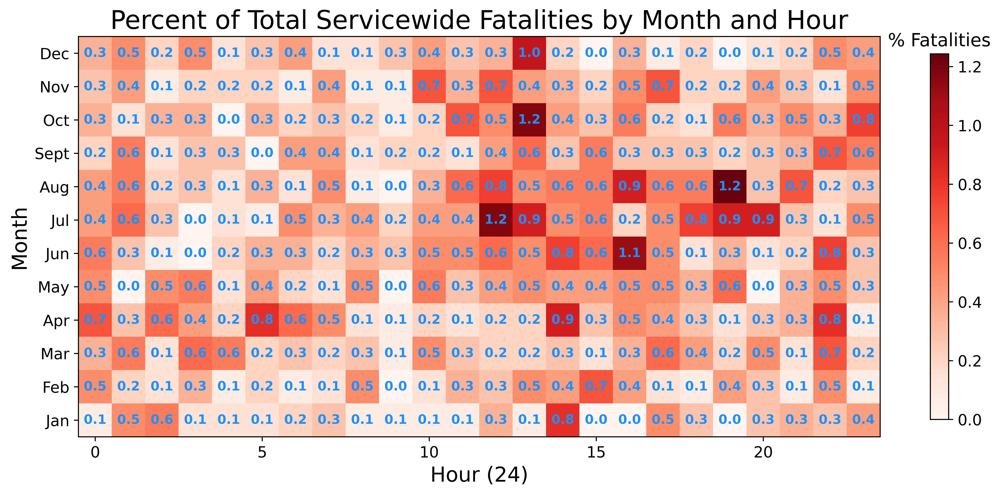

In [26]:
fig, ax = plt.subplots(figsize=(14,7), dpi=600)
im = ax.imshow(allfatals_array_reorder_perc, cmap = "Reds") # note: 'jet' is blue to red color gradient
months = ['Dec','Nov','Oct','Sept','Aug','Jul','Jun','May','Apr','Mar','Feb','Jan']
plt.yticks(range(len(months)), months, fontsize = 12)
plt.xticks(fontsize = 12)
cbar = ax.figure.colorbar(im, shrink = 0.75)
cbar.ax.set_title('% Fatalities', fontsize = 14)
cbar.ax.tick_params(labelsize=12)
ax.set_xlabel("Hour (24)", fontsize = 16)
ax.set_ylabel("Month", fontsize = 16)
ax.set_title("Percent of Total Servicewide Fatalities by Month and Hour", size = 20)

for i in range(len(months)):
    for j in range(24):
        text = ax.text(j, i, round(allfatals_array_reorder_perc[i, j],1), ha="center", va="center", color="dodgerblue", weight='bold')

## Percentage of Crashes Involving Animals

In [19]:
# 2D heatmap - requires numpy array of just Z values from  3D plot, see example here: https://datavizpyr.com/heatmap-with-matplotlib-in-python/
# query Count values for each hour, to become columns of array (months are already in order, so rows of array are all set)

animal = analysis_2024.loc[analysis_2024['Involving Animal']==1.0]
animalcount = animal[['HOUR','MONTH']]
animalcount['Count'] = 1
animalcount_agg = animalcount.groupby(['MONTH','HOUR']).sum().reset_index()
midnight_animalcount = animalcount_agg['Count'].loc[animalcount_agg['HOUR']==0.0]
one_animalcount = animalcount_agg['Count'].loc[animalcount_agg['HOUR']==1.0]
two_animalcount = animalcount_agg['Count'].loc[animalcount_agg['HOUR']==2.0]
three_animalcount = animalcount_agg['Count'].loc[animalcount_agg['HOUR']==3.0]
four_animalcount = animalcount_agg['Count'].loc[animalcount_agg['HOUR']==4.0]
five_animalcount = animalcount_agg['Count'].loc[animalcount_agg['HOUR']==5.0]
six_animalcount = animalcount_agg['Count'].loc[animalcount_agg['HOUR']==6.0]
seven_animalcount = animalcount_agg['Count'].loc[animalcount_agg['HOUR']==7.0]
eight_animalcount = animalcount_agg['Count'].loc[animalcount_agg['HOUR']==8.0]
nine_animalcount = animalcount_agg['Count'].loc[animalcount_agg['HOUR']==9.0]
ten_animalcount = animalcount_agg['Count'].loc[animalcount_agg['HOUR']==10.0]
eleven_animalcount = animalcount_agg['Count'].loc[animalcount_agg['HOUR']==11.0]
twelve_animalcount = animalcount_agg['Count'].loc[animalcount_agg['HOUR']==12.0]
thirteen_animalcount = animalcount_agg['Count'].loc[animalcount_agg['HOUR']==13.0]
fourteen_animalcount = animalcount_agg['Count'].loc[animalcount_agg['HOUR']==14.0]
fifteen_animalcount = animalcount_agg['Count'].loc[animalcount_agg['HOUR']==15.0]
sixteen_animalcount = animalcount_agg['Count'].loc[animalcount_agg['HOUR']==16.0]
seventeen_animalcount = animalcount_agg['Count'].loc[animalcount_agg['HOUR']==17.0]
eighteen_animalcount = animalcount_agg['Count'].loc[animalcount_agg['HOUR']==18.0]
nineteen_animalcount = animalcount_agg['Count'].loc[animalcount_agg['HOUR']==19.0]
twenty_animalcount = animalcount_agg['Count'].loc[animalcount_agg['HOUR']==20.0]
twentyone_animalcount = animalcount_agg['Count'].loc[animalcount_agg['HOUR']==21.0]
twentytwo_animalcount = animalcount_agg['Count'].loc[animalcount_agg['HOUR']==22.0]
twentythree_animalcount = animalcount_agg['Count'].loc[animalcount_agg['HOUR']==23.0]

# combine columns into wide array
animalcount_array = pd.DataFrame(np.column_stack([midnight_animalcount,one_animalcount,two_animalcount,three_animalcount,four_animalcount,five_animalcount,six_animalcount,seven_animalcount,eight_animalcount,nine_animalcount,ten_animalcount,eleven_animalcount,twelve_animalcount,thirteen_animalcount,fourteen_animalcount,fifteen_animalcount,sixteen_animalcount,seventeen_animalcount,eighteen_animalcount,nineteen_animalcount,twenty_animalcount,twentyone_animalcount,twentytwo_animalcount,twentythree_animalcount]), columns=['midnight_animalcount','one_animalcount','two_animalcount','three_animalcount','four_animalcount','five_animalcount','six_animalcount','seven_animalcount','eight_animalcount','nine_animalcount','ten_animalcount','eleven_animalcount','twelve_animalcount','thirteen_animalcount','fourteen_animalcount','fifteen_animalcount','sixteen_animalcount','seventeen_animalcount','eighteen_animalcount','nineteen_animalcount','twenty_animalcount','twentyone_animalcount','twentytwo_animalcount','twentythree_animalcount'])
animalcount_array.head()

<ipython-input-19-279642d05c9a>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  animalcount['Count'] = 1


,midnight_animalcount,one_animalcount,two_animalcount,three_animalcount,four_animalcount,five_animalcount,six_animalcount,seven_animalcount,eight_animalcount,nine_animalcount,...,fourteen_animalcount,fifteen_animalcount,sixteen_animalcount,seventeen_animalcount,eighteen_animalcount,nineteen_animalcount,twenty_animalcount,twentyone_animalcount,twentytwo_animalcount,twentythree_animalcount
0,27,28,13,14,14,35,80,90,68,42,...,28,35,44,165,177,86,51,45,66,42
1,27,26,19,11,15,37,71,53,39,31,...,32,29,27,76,204,103,72,39,24,43
2,27,23,23,14,15,25,81,46,69,41,...,32,31,34,47,155,156,83,60,45,27
3,25,38,14,25,12,40,105,64,39,29,...,28,41,34,29,46,88,145,66,51,44
4,42,32,29,22,17,59,61,57,54,60,...,55,75,48,61,53,84,127,146,85,61


In [20]:
# set index
animalcount_array['month']=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sept','Oct','Nov','Dec']
animalcount_array = animalcount_array.set_index('month')
animalcount_array.head()

,midnight_animalcount,one_animalcount,two_animalcount,three_animalcount,four_animalcount,five_animalcount,six_animalcount,seven_animalcount,eight_animalcount,nine_animalcount,...,fourteen_animalcount,fifteen_animalcount,sixteen_animalcount,seventeen_animalcount,eighteen_animalcount,nineteen_animalcount,twenty_animalcount,twentyone_animalcount,twentytwo_animalcount,twentythree_animalcount
month,,,,,,,,,,,,,,,,,,,,,
Jan,27,28,13,14,14,35,80,90,68,42,...,28,35,44,165,177,86,51,45,66,42
Feb,27,26,19,11,15,37,71,53,39,31,...,32,29,27,76,204,103,72,39,24,43
Mar,27,23,23,14,15,25,81,46,69,41,...,32,31,34,47,155,156,83,60,45,27
Apr,25,38,14,25,12,40,105,64,39,29,...,28,41,34,29,46,88,145,66,51,44
May,42,32,29,22,17,59,61,57,54,60,...,55,75,48,61,53,84,127,146,85,61


In [21]:
# reverse row index so months match order in FHWA EDC-7 plots
animalcount_array_reorder = np.flipud(animalcount_array)
animalcount_array_reorder

array([[ 37,  24,  20,  22,  45,  39,  89, 101,  64,  71,  48,  74,  52,
         39,  49,  50,  92, 313, 212, 137,  77,  75,  63,  55],
       [ 79,  62,  49,  37,  36,  81, 188, 145, 107,  99,  65,  78,  95,
         62,  65,  65, 148, 434, 364, 197, 137, 137, 113,  84],
       [ 97,  66,  39,  44,  47,  66, 175, 189, 146,  71,  98,  95,  84,
         56,  74,  80, 125, 179, 291, 422, 212, 127, 127,  86],
       [ 60,  44,  29,  24,  27,  49, 149, 131, 105, 113, 104,  89,  84,
         81,  84,  86, 110, 120, 143, 303, 380, 171,  80,  76],
       [ 59,  30,  32,  24,  27,  65,  92,  98,  78,  85, 122, 124, 105,
         84,  97,  93, 119, 101, 107, 128, 245, 356, 127,  93],
       [ 65,  31,  34,  27,  38,  82, 100, 101,  96, 124, 141, 110,  94,
         87, 120, 104, 117, 104,  99, 112, 168, 293, 242, 134],
       [ 56,  38,  36,  28,  31,  55,  60,  73,  87, 100,  80, 105,  91,
         73,  73,  82,  89,  96,  76,  99, 129, 238, 200,  97],
       [ 42,  32,  29,  22,  17,  59,  61

In [22]:
animaltotalcrashcount = animal.shape[0]
animalcount_array_reorder_perc = animalcount_array_reorder/animaltotalcrashcount*100

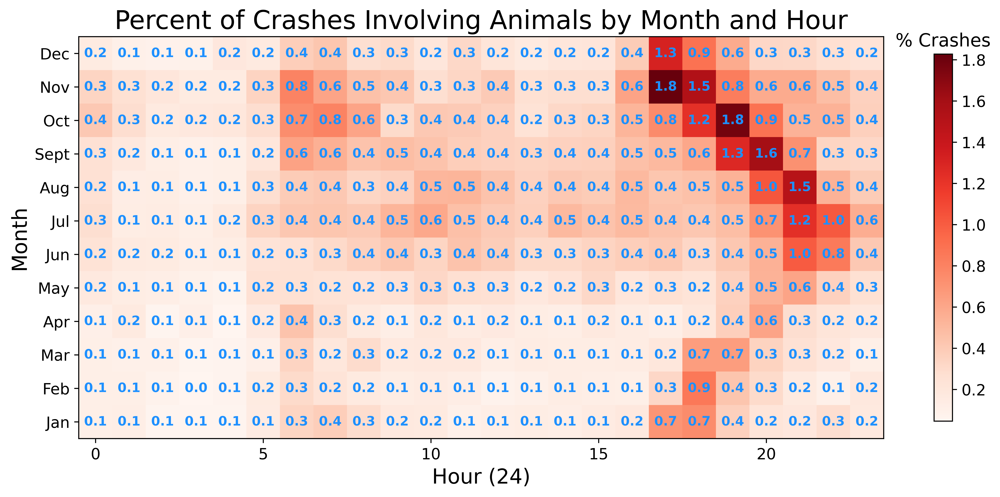

In [23]:
fig, ax = plt.subplots(figsize=(14,7), dpi=600)
im = ax.imshow(animalcount_array_reorder_perc, cmap = "Reds") # note: 'jet' is blue to red color gradient
months = ['Dec','Nov','Oct','Sept','Aug','Jul','Jun','May','Apr','Mar','Feb','Jan']
plt.yticks(range(len(months)), months, fontsize = 12)
plt.xticks(fontsize = 12)
cbar = ax.figure.colorbar(im, shrink = 0.75)
cbar.ax.set_title('% Crashes', fontsize = 14)
cbar.ax.tick_params(labelsize=12)
ax.set_xlabel("Hour (24)", fontsize = 16)
ax.set_ylabel("Month", fontsize = 16)
ax.set_title("Percent of Crashes Involving Animals by Month and Hour", size = 20)

for i in range(len(months)):
    for j in range(24):
        text = ax.text(j, i, round(animalcount_array_reorder_perc[i, j],1), ha="center", va="center", color="dodgerblue", weight="bold")

## Percent of Crashes Involving Motorcycles

In [47]:
motorcycle = analysis_2024.loc[analysis_2024['Motorcycle_Ind']==1.0]
motorcyclecount = motorcycle[['HOUR','MONTH']] # X and Y dimensions of surface plot
motorcyclecount['Count'] = 1 # Z dimension of surface plot
motorcyclecount_agg = motorcyclecount.groupby(['MONTH','HOUR']).sum().reset_index()
motorcyclecount_agg.to_csv("./motorcyclecount_agg.csv", index=False)

<ipython-input-47-7aad7c6f0561>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  motorcyclecount['Count'] = 1 # Z dimension of surface plot


In [49]:
# 2D heatmap - requires numpy array of just Z values from  3D plot, see example here: https://datavizpyr.com/heatmap-with-matplotlib-in-python/
# query Count values for each hour, to become columns of array (months are already in order, so rows of array are all set)

motorcyclecount_agg = pd.read_csv("./manually fixed data/motorcyclecount_agg.csv")

midnight_motorcyclecount = motorcyclecount_agg['Count'].loc[motorcyclecount_agg['HOUR']==0.0]
one_motorcyclecount = motorcyclecount_agg['Count'].loc[motorcyclecount_agg['HOUR']==1.0]
two_motorcyclecount = motorcyclecount_agg['Count'].loc[motorcyclecount_agg['HOUR']==2.0]
three_motorcyclecount = motorcyclecount_agg['Count'].loc[motorcyclecount_agg['HOUR']==3.0]
four_motorcyclecount = motorcyclecount_agg['Count'].loc[motorcyclecount_agg['HOUR']==4.0]
five_motorcyclecount = motorcyclecount_agg['Count'].loc[motorcyclecount_agg['HOUR']==5.0]
six_motorcyclecount = motorcyclecount_agg['Count'].loc[motorcyclecount_agg['HOUR']==6.0]
seven_motorcyclecount = motorcyclecount_agg['Count'].loc[motorcyclecount_agg['HOUR']==7.0]
eight_motorcyclecount = motorcyclecount_agg['Count'].loc[motorcyclecount_agg['HOUR']==8.0]
nine_motorcyclecount = motorcyclecount_agg['Count'].loc[motorcyclecount_agg['HOUR']==9.0]
ten_motorcyclecount = motorcyclecount_agg['Count'].loc[motorcyclecount_agg['HOUR']==10.0]
eleven_motorcyclecount = motorcyclecount_agg['Count'].loc[motorcyclecount_agg['HOUR']==11.0]
twelve_motorcyclecount = motorcyclecount_agg['Count'].loc[motorcyclecount_agg['HOUR']==12.0]
thirteen_motorcyclecount = motorcyclecount_agg['Count'].loc[motorcyclecount_agg['HOUR']==13.0]
fourteen_motorcyclecount = motorcyclecount_agg['Count'].loc[motorcyclecount_agg['HOUR']==14.0]
fifteen_motorcyclecount = motorcyclecount_agg['Count'].loc[motorcyclecount_agg['HOUR']==15.0]
sixteen_motorcyclecount = motorcyclecount_agg['Count'].loc[motorcyclecount_agg['HOUR']==16.0]
seventeen_motorcyclecount = motorcyclecount_agg['Count'].loc[motorcyclecount_agg['HOUR']==17.0]
eighteen_motorcyclecount = motorcyclecount_agg['Count'].loc[motorcyclecount_agg['HOUR']==18.0]
nineteen_motorcyclecount = motorcyclecount_agg['Count'].loc[motorcyclecount_agg['HOUR']==19.0]
twenty_motorcyclecount = motorcyclecount_agg['Count'].loc[motorcyclecount_agg['HOUR']==20.0]
twentyone_motorcyclecount = motorcyclecount_agg['Count'].loc[motorcyclecount_agg['HOUR']==21.0]
twentytwo_motorcyclecount = motorcyclecount_agg['Count'].loc[motorcyclecount_agg['HOUR']==22.0]
twentythree_motorcyclecount = motorcyclecount_agg['Count'].loc[motorcyclecount_agg['HOUR']==23.0]

# combine columns into wide array
motorcyclecount_array = pd.DataFrame(np.column_stack([midnight_motorcyclecount,one_motorcyclecount,two_motorcyclecount,three_motorcyclecount,four_motorcyclecount,five_motorcyclecount,six_motorcyclecount,seven_motorcyclecount,eight_motorcyclecount,nine_motorcyclecount,ten_motorcyclecount,eleven_motorcyclecount,twelve_motorcyclecount,thirteen_motorcyclecount,fourteen_motorcyclecount,fifteen_motorcyclecount,sixteen_motorcyclecount,seventeen_motorcyclecount,eighteen_motorcyclecount,nineteen_motorcyclecount,twenty_motorcyclecount,twentyone_motorcyclecount,twentytwo_motorcyclecount,twentythree_motorcyclecount]), columns=['midnight_motorcyclecount','one_motorcyclecount','two_motorcyclecount','three_motorcyclecount','four_motorcyclecount','five_motorcyclecount','six_motorcyclecount','seven_motorcyclecount','eight_motorcyclecount','nine_motorcyclecount','ten_motorcyclecount','eleven_motorcyclecount','twelve_motorcyclecount','thirteen_motorcyclecount','fourteen_motorcyclecount','fifteen_motorcyclecount','sixteen_motorcyclecount','seventeen_motorcyclecount','eighteen_motorcyclecount','nineteen_motorcyclecount','twenty_motorcyclecount','twentyone_motorcyclecount','twentytwo_motorcyclecount','twentythree_motorcyclecount'])
motorcyclecount_array.head()

,midnight_motorcyclecount,one_motorcyclecount,two_motorcyclecount,three_motorcyclecount,four_motorcyclecount,five_motorcyclecount,six_motorcyclecount,seven_motorcyclecount,eight_motorcyclecount,nine_motorcyclecount,...,fourteen_motorcyclecount,fifteen_motorcyclecount,sixteen_motorcyclecount,seventeen_motorcyclecount,eighteen_motorcyclecount,nineteen_motorcyclecount,twenty_motorcyclecount,twentyone_motorcyclecount,twentytwo_motorcyclecount,twentythree_motorcyclecount
0,2,0,0,0,1,2,3,1,2,6,...,23,18,12,15,3,4,6,1,0,2
1,0,1,1,0,1,0,0,1,4,3,...,20,22,22,14,10,6,2,3,2,1
2,4,2,0,0,0,3,1,4,7,9,...,34,33,43,31,17,13,5,10,4,0
3,1,2,0,3,2,1,8,3,13,6,...,50,52,59,48,43,21,13,17,6,3
4,6,7,5,3,6,2,8,12,24,33,...,91,74,116,74,61,38,31,17,11,14


In [50]:
# set index
motorcyclecount_array['month']=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sept','Oct','Nov','Dec']
motorcyclecount_array = motorcyclecount_array.set_index('month')
motorcyclecount_array.head()

,midnight_motorcyclecount,one_motorcyclecount,two_motorcyclecount,three_motorcyclecount,four_motorcyclecount,five_motorcyclecount,six_motorcyclecount,seven_motorcyclecount,eight_motorcyclecount,nine_motorcyclecount,...,fourteen_motorcyclecount,fifteen_motorcyclecount,sixteen_motorcyclecount,seventeen_motorcyclecount,eighteen_motorcyclecount,nineteen_motorcyclecount,twenty_motorcyclecount,twentyone_motorcyclecount,twentytwo_motorcyclecount,twentythree_motorcyclecount
month,,,,,,,,,,,,,,,,,,,,,
Jan,2,0,0,0,1,2,3,1,2,6,...,23,18,12,15,3,4,6,1,0,2
Feb,0,1,1,0,1,0,0,1,4,3,...,20,22,22,14,10,6,2,3,2,1
Mar,4,2,0,0,0,3,1,4,7,9,...,34,33,43,31,17,13,5,10,4,0
Apr,1,2,0,3,2,1,8,3,13,6,...,50,52,59,48,43,21,13,17,6,3
May,6,7,5,3,6,2,8,12,24,33,...,91,74,116,74,61,38,31,17,11,14


In [51]:
# reverse row index so months match order in FHWA EDC-7 plots
motorcyclecount_array_reorder = np.flipud(motorcyclecount_array)
motorcyclecount_array_reorder

array([[  2,   0,   0,   0,   0,   1,   2,   1,   1,   1,   5,  10,  10,
         15,  17,  17,  14,   6,   9,   4,   1,   2,   4,   7],
       [  0,   1,   0,   3,   2,   0,   2,   9,   7,   9,  14,  15,  26,
         37,  33,  24,  34,  14,   9,   8,   5,   3,   1,   3],
       [  1,   8,   1,   1,   0,   1,   6,   8,  11,  18,  34,  67,  58,
         73,  85,  75,  85,  66,  39,  38,  18,  14,   3,   7],
       [ 11,   7,   4,   2,   4,   6,  11,  10,  17,  33,  61,  98, 100,
        110, 113, 133, 105, 127,  78,  48,  23,  24,   8,   7],
       [ 14,   7,  14,   3,   4,   8,   8,  18,  36,  35,  80, 125, 132,
        153, 146, 133, 131, 119,  86,  46,  40,  39,  16,  16],
       [ 23,  15,   7,   2,   9,   9,  13,  13,  23,  49,  74,  98, 130,
        123, 124, 154, 121, 110,  94,  62,  46,  31,  15,  16],
       [ 15,   9,   8,   6,   5,   6,  10,  13,  19,  40,  68,  86,  91,
        115, 119, 135, 117, 110,  77,  45,  39,  25,  11,  11],
       [  6,   7,   5,   3,   6,   2,   8

In [54]:
motorcycletotalcrashcount = motorcycle.shape[0]
motorcyclecount_array_reorder_perc = motorcyclecount_array_reorder/motorcycletotalcrashcount*100

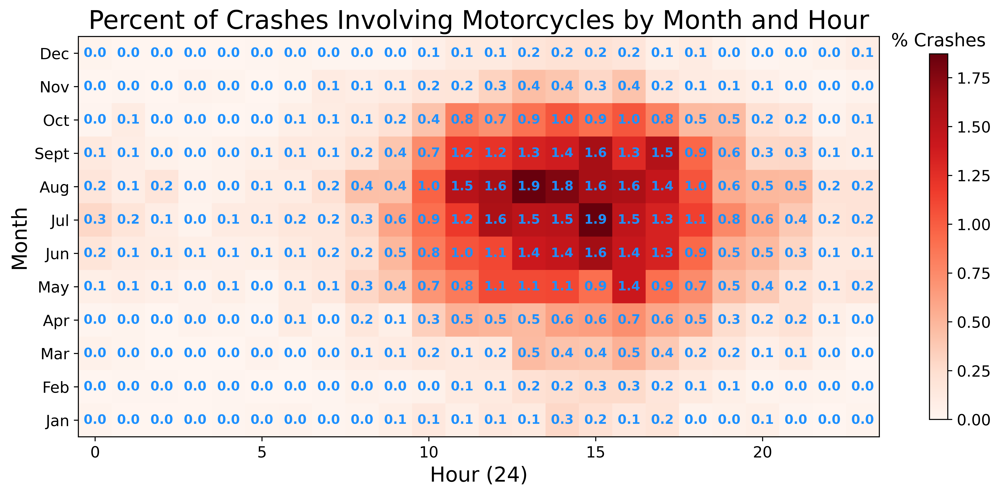

In [55]:
fig, ax = plt.subplots(figsize=(14,7), dpi=600)
im = ax.imshow(motorcyclecount_array_reorder_perc, cmap = "Reds") # note: 'jet' is blue to red color gradient
months = ['Dec','Nov','Oct','Sept','Aug','Jul','Jun','May','Apr','Mar','Feb','Jan']
plt.yticks(range(len(months)), months, fontsize = 12)
plt.xticks(fontsize = 12)
cbar = ax.figure.colorbar(im, shrink = 0.75)
cbar.ax.set_title('% Crashes', fontsize = 14)
cbar.ax.tick_params(labelsize=12)
ax.set_xlabel("Hour (24)", fontsize = 16)
ax.set_ylabel("Month", fontsize = 16)
ax.set_title("Percent of Crashes Involving Motorcycles by Month and Hour", size = 20)

for i in range(len(months)):
    for j in range(24):
        text = ax.text(j, i, round(motorcyclecount_array_reorder_perc[i, j],1), ha="center", va="center", color="dodgerblue", weight="bold")

## Percent of Crashes involving VRUs

In [41]:
vru = analysis_2024.loc[analysis_2024['VRU']==1.0]
VRUcount = vru[['HOUR','MONTH']]
VRUcount['Count'] = 1
VRUcount_agg = VRUcount.groupby(['MONTH','HOUR']).sum().reset_index()
VRUcount_agg.to_csv('VRUcount_agg.csv', index=False)

<ipython-input-41-e875249cbb62>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  VRUcount['Count'] = 1


In [42]:
# 2D heatmap - requires numpy array of just Z values from  3D plot, see example here: https://datavizpyr.com/heatmap-with-matplotlib-in-python/
# query Count values for each hour, to become columns of array (months are already in order, so rows of array are all set)

VRUcount_agg = pd.read_csv('./manually fixed data/VRUcount_agg.csv')

midnight_VRUcount = VRUcount_agg['Count'].loc[VRUcount_agg['HOUR']==0.0]
one_VRUcount = VRUcount_agg['Count'].loc[VRUcount_agg['HOUR']==1.0]
two_VRUcount = VRUcount_agg['Count'].loc[VRUcount_agg['HOUR']==2.0]
three_VRUcount = VRUcount_agg['Count'].loc[VRUcount_agg['HOUR']==3.0]
four_VRUcount = VRUcount_agg['Count'].loc[VRUcount_agg['HOUR']==4.0]
five_VRUcount = VRUcount_agg['Count'].loc[VRUcount_agg['HOUR']==5.0]
six_VRUcount = VRUcount_agg['Count'].loc[VRUcount_agg['HOUR']==6.0]
seven_VRUcount = VRUcount_agg['Count'].loc[VRUcount_agg['HOUR']==7.0]
eight_VRUcount = VRUcount_agg['Count'].loc[VRUcount_agg['HOUR']==8.0]
nine_VRUcount = VRUcount_agg['Count'].loc[VRUcount_agg['HOUR']==9.0]
ten_VRUcount = VRUcount_agg['Count'].loc[VRUcount_agg['HOUR']==10.0]
eleven_VRUcount = VRUcount_agg['Count'].loc[VRUcount_agg['HOUR']==11.0]
twelve_VRUcount = VRUcount_agg['Count'].loc[VRUcount_agg['HOUR']==12.0]
thirteen_VRUcount = VRUcount_agg['Count'].loc[VRUcount_agg['HOUR']==13.0]
fourteen_VRUcount = VRUcount_agg['Count'].loc[VRUcount_agg['HOUR']==14.0]
fifteen_VRUcount = VRUcount_agg['Count'].loc[VRUcount_agg['HOUR']==15.0]
sixteen_VRUcount = VRUcount_agg['Count'].loc[VRUcount_agg['HOUR']==16.0]
seventeen_VRUcount = VRUcount_agg['Count'].loc[VRUcount_agg['HOUR']==17.0]
eighteen_VRUcount = VRUcount_agg['Count'].loc[VRUcount_agg['HOUR']==18.0]
nineteen_VRUcount = VRUcount_agg['Count'].loc[VRUcount_agg['HOUR']==19.0]
twenty_VRUcount = VRUcount_agg['Count'].loc[VRUcount_agg['HOUR']==20.0]
twentyone_VRUcount = VRUcount_agg['Count'].loc[VRUcount_agg['HOUR']==21.0]
twentytwo_VRUcount = VRUcount_agg['Count'].loc[VRUcount_agg['HOUR']==22.0]
twentythree_VRUcount = VRUcount_agg['Count'].loc[VRUcount_agg['HOUR']==23.0]

# combine columns into wide array
VRUcount_array = pd.DataFrame(np.column_stack([midnight_VRUcount,one_VRUcount,two_VRUcount,three_VRUcount,four_VRUcount,five_VRUcount,six_VRUcount,seven_VRUcount,eight_VRUcount,nine_VRUcount,ten_VRUcount,eleven_VRUcount,twelve_VRUcount,thirteen_VRUcount,fourteen_VRUcount,fifteen_VRUcount,sixteen_VRUcount,seventeen_VRUcount,eighteen_VRUcount,nineteen_VRUcount,twenty_VRUcount,twentyone_VRUcount,twentytwo_VRUcount,twentythree_VRUcount]), columns=['midnight_VRUcount','one_VRUcount','two_VRUcount','three_VRUcount','four_VRUcount','five_VRUcount','six_VRUcount','seven_VRUcount','eight_VRUcount','nine_VRUcount','ten_VRUcount','eleven_VRUcount','twelve_VRUcount','thirteen_VRUcount','fourteen_VRUcount','fifteen_VRUcount','sixteen_VRUcount','seventeen_VRUcount','eighteen_VRUcount','nineteen_VRUcount','twenty_VRUcount','twentyone_VRUcount','twentytwo_VRUcount','twentythree_VRUcount'])
VRUcount_array.head()

,midnight_VRUcount,one_VRUcount,two_VRUcount,three_VRUcount,four_VRUcount,five_VRUcount,six_VRUcount,seven_VRUcount,eight_VRUcount,nine_VRUcount,...,fourteen_VRUcount,fifteen_VRUcount,sixteen_VRUcount,seventeen_VRUcount,eighteen_VRUcount,nineteen_VRUcount,twenty_VRUcount,twentyone_VRUcount,twentytwo_VRUcount,twentythree_VRUcount
0,0,3,0,1,0,0,5,4,4,2,...,13,4,13,7,5,6,1,1,1,1
1,0,0,0,1,2,0,7,2,11,3,...,10,9,9,7,12,0,0,1,4,0
2,0,1,1,2,1,1,4,4,5,3,...,6,9,13,11,9,2,2,1,0,6
3,1,1,1,1,0,2,2,3,9,2,...,17,16,24,12,7,13,4,10,3,5
4,2,3,1,1,0,0,0,3,7,9,...,18,20,23,26,20,15,9,3,3,3


In [43]:
# set index
VRUcount_array['month']=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sept','Oct','Nov','Dec']
VRUcount_array = VRUcount_array.set_index('month')
VRUcount_array.head()

,midnight_VRUcount,one_VRUcount,two_VRUcount,three_VRUcount,four_VRUcount,five_VRUcount,six_VRUcount,seven_VRUcount,eight_VRUcount,nine_VRUcount,...,fourteen_VRUcount,fifteen_VRUcount,sixteen_VRUcount,seventeen_VRUcount,eighteen_VRUcount,nineteen_VRUcount,twenty_VRUcount,twentyone_VRUcount,twentytwo_VRUcount,twentythree_VRUcount
month,,,,,,,,,,,,,,,,,,,,,
Jan,0,3,0,1,0,0,5,4,4,2,...,13,4,13,7,5,6,1,1,1,1
Feb,0,0,0,1,2,0,7,2,11,3,...,10,9,9,7,12,0,0,1,4,0
Mar,0,1,1,2,1,1,4,4,5,3,...,6,9,13,11,9,2,2,1,0,6
Apr,1,1,1,1,0,2,2,3,9,2,...,17,16,24,12,7,13,4,10,3,5
May,2,3,1,1,0,0,0,3,7,9,...,18,20,23,26,20,15,9,3,3,3


In [44]:
# reverse row index so months match order in FHWA EDC-7 plots
VRUcount_array_reorder = np.flipud(VRUcount_array)
VRUcount_array_reorder

array([[ 2,  0,  4,  0,  0,  1,  1,  8,  2,  7,  3,  5,  5, 10,  5,  6,
         6, 21,  1,  2,  3,  1,  8,  0],
       [ 1,  1,  2,  0,  1,  0,  2,  1,  5,  0,  6,  8, 11, 10,  9,  4,
         9, 10,  9,  5,  1,  3,  2,  3],
       [ 3,  2,  0,  0,  1,  2,  6,  5, 13,  8,  7, 17, 15, 11, 15, 10,
        14, 20, 10, 11,  8,  2,  2,  2],
       [ 2,  0,  2,  0,  1,  0,  2,  2,  7, 13,  9, 16, 12, 19, 15, 24,
        22, 23, 21, 11,  7,  4,  3,  8],
       [ 9,  0,  2,  2,  0,  4,  6, 11, 11, 12, 27, 19, 25, 28, 27, 29,
        28, 20, 14, 12,  9,  5,  3,  2],
       [ 1,  4,  1,  1,  0,  3,  2,  6, 11, 11, 18, 17, 27, 28, 20, 26,
        22, 35, 23, 12,  9,  4, 12,  3],
       [ 2,  2,  0,  0,  0,  0,  0, 10,  6,  9, 11, 18, 28, 18, 23, 22,
        12, 30, 19, 12, 17,  2,  9,  1],
       [ 2,  3,  1,  1,  0,  0,  0,  3,  7,  9, 10, 14, 17, 20, 18, 20,
        23, 26, 20, 15,  9,  3,  3,  3],
       [ 1,  1,  1,  1,  0,  2,  2,  3,  9,  2,  9, 14, 18, 10, 17, 16,
        24, 12,  7, 13, 

In [45]:
VRUtotalcrashcount = vru.shape[0]
VRUcount_array_reorder_perc = VRUcount_array_reorder/VRUtotalcrashcount*100

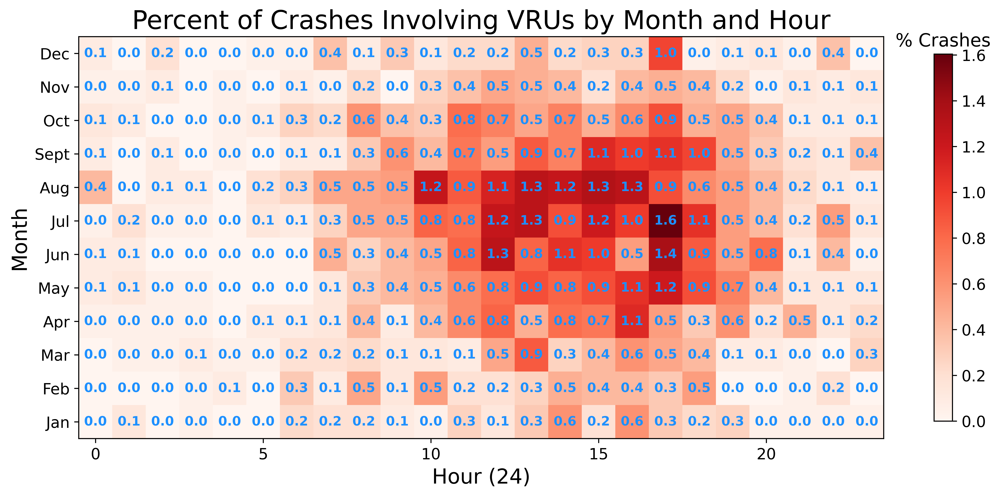

In [46]:
fig, ax = plt.subplots(figsize=(14,7), dpi=600)
im = ax.imshow(VRUcount_array_reorder_perc, cmap = "Reds") # note: 'jet' is blue to red color gradient
months = ['Dec','Nov','Oct','Sept','Aug','Jul','Jun','May','Apr','Mar','Feb','Jan']
plt.yticks(range(len(months)), months, fontsize = 12)
plt.xticks(fontsize = 12)
cbar = ax.figure.colorbar(im, shrink = 0.75)
cbar.ax.set_title('% Crashes', fontsize = 14)
cbar.ax.tick_params(labelsize=12)
ax.set_xlabel("Hour (24)", fontsize = 16)
ax.set_ylabel("Month", fontsize = 16)
ax.set_title("Percent of Crashes Involving VRUs by Month and Hour", size = 20)

for i in range(len(months)):
    for j in range(24):
        text = ax.text(j, i, round(VRUcount_array_reorder_perc[i, j],1), ha="center", va="center", color="dodgerblue", weight = 'bold')

# Pie Chart

Text(0.5, 1.0, 'All Lighting Conditions')

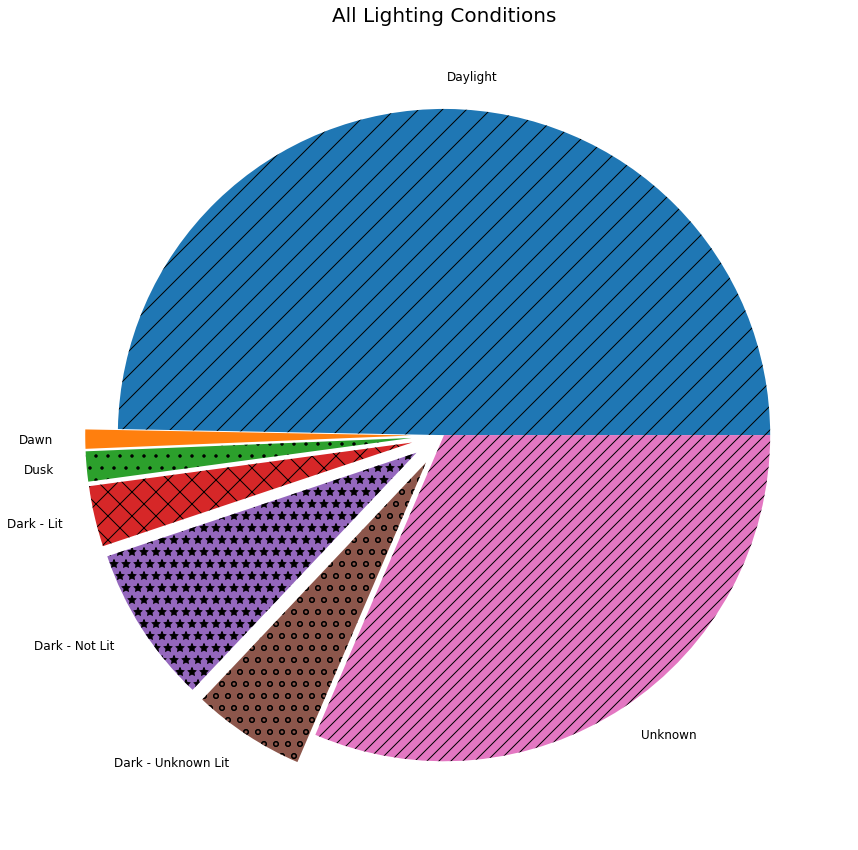

In [4]:
labels = 'Daylight', 'Dawn', 'Dusk', 'Dark - Lit', 'Dark - Not Lit', 'Dark - Unknown Lit', 'Unknown'
sizes = [analysis_2024['Daylight'].sum(), analysis_2024['Dawn'].sum(), analysis_2024['Dusk'].sum(), analysis_2024['Dark_Lit'].sum(), analysis_2024['Dark_NotLit'].sum(), analysis_2024['Dark_UnknownLit'].sum(), analysis_2024['UnknownBlankNullLit'].sum()]
explode = (0, 0.1, 0.1, 0.1, 0.1, 0.1, 0) # determine which slices to pop out (in order)

fig, ax = plt.subplots(figsize=(15,15))
ax.pie(sizes, labels=labels,  textprops={'fontsize': 12}, labeldistance=1.1, explode=explode, hatch=['/', '', '.', 'x', '*', 'o', '//'])#, autopct='%1.1f%%', pctdistance=1.3)
ax.set_title("All Lighting Conditions", fontsize=20)

Text(0.5, 1.0, 'General Lighting Condition')

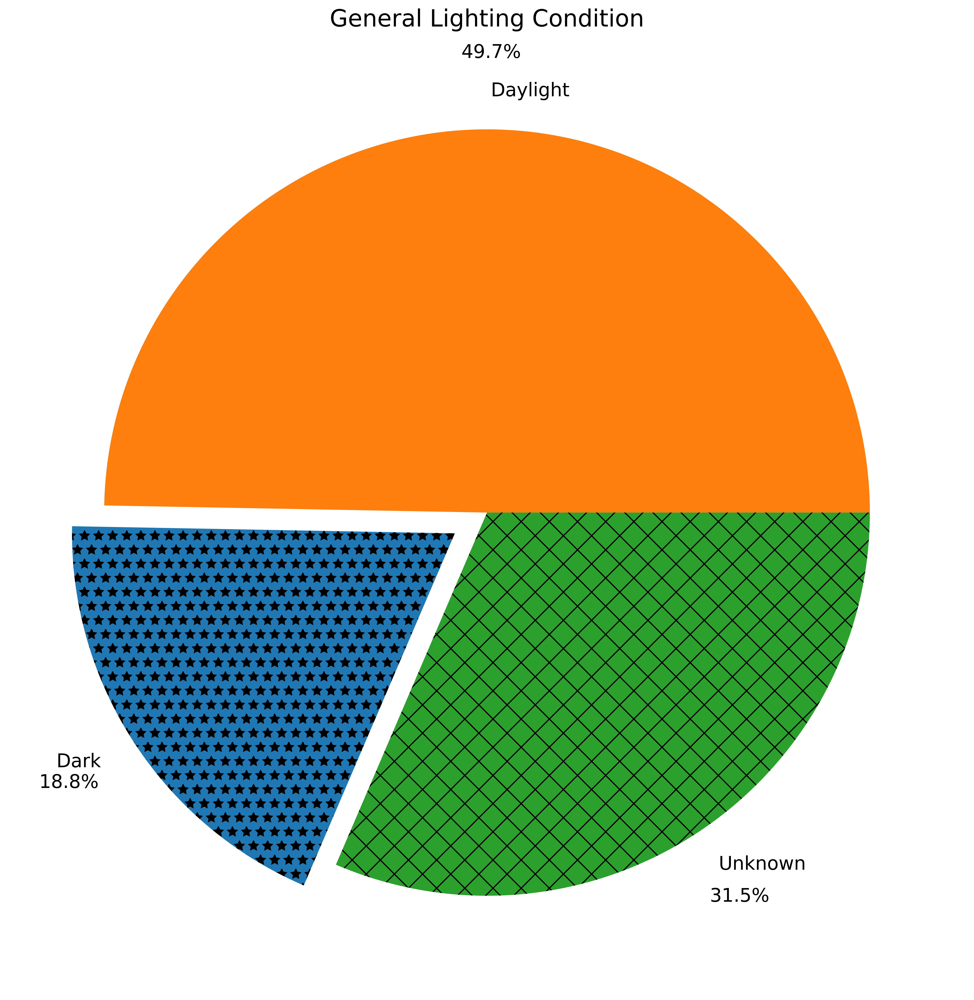

In [5]:
labels = 'Daylight', 'Dark', 'Unknown'
sizes = [analysis_2024['Daylight'].sum(), analysis_2024['Poor Lighting'].sum(), analysis_2024['UnknownBlankNullLit'].sum()]
explode = (0, 0.1, 0) # determine which slices to pop out (in order)

fig, ax = plt.subplots(figsize=(15,15), dpi=600)
ax.pie(sizes, labels=labels, textprops={'fontsize': 16}, autopct='%1.1f%%', pctdistance=1.2, explode=explode, colors = ['tab:orange','tab:blue','tab:green'], hatch=['', '*', 'x'])
ax.set_title("General Lighting Condition", fontsize=20)

Text(0.5, 1.0, 'Known Lighting Condition')

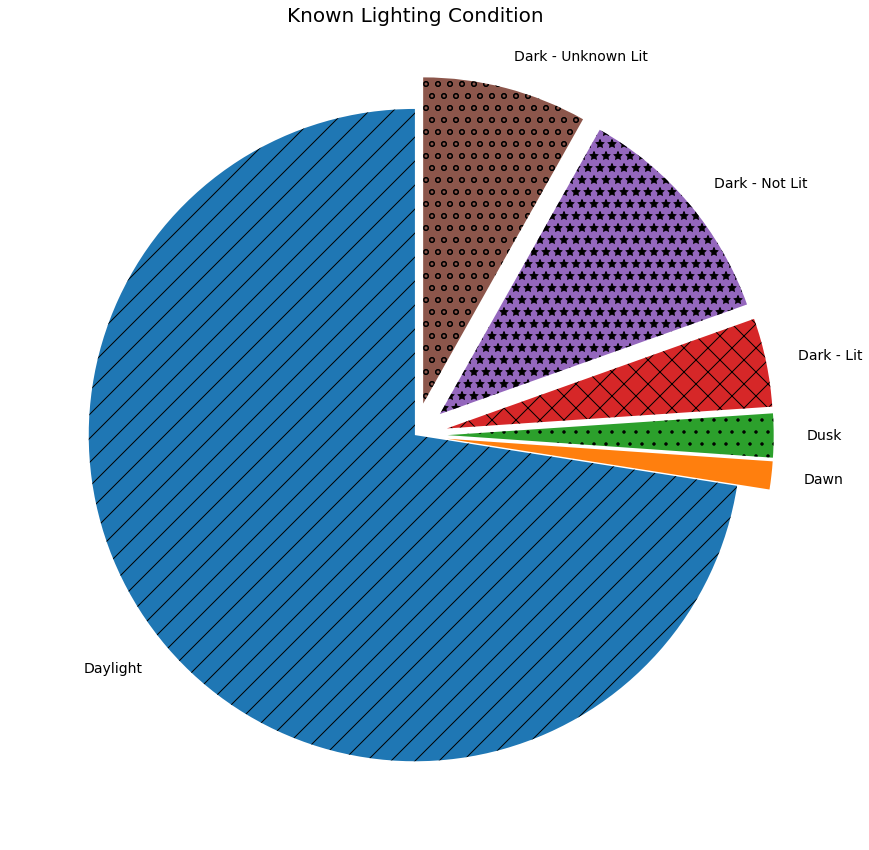

In [74]:
labels = 'Daylight', 'Dawn', 'Dusk', 'Dark - Lit', 'Dark - Not Lit', 'Dark - Unknown Lit'
sizes = [analysis_2024['Daylight'].sum(), analysis_2024['Dawn'].sum(), analysis_2024['Dusk'].sum(), analysis_2024['Dark_Lit'].sum(), analysis_2024['Dark_NotLit'].sum(), analysis_2024['Dark_UnknownLit'].sum()]
explode = (0, 0.1, 0.1, 0.1, 0.1, 0.1) # determine which slices to pop out (in order)

fig, ax = plt.subplots(figsize=(15,15))
ax.pie(sizes, labels=labels, textprops={'fontsize': 14}, explode=explode, hatch=['/', '', '.', 'x', '*', 'o'], startangle=90)#, autopct='%1.1f%%', pctdistance=1.2)
ax.set_title("Known Lighting Condition", fontsize=20)

# Poor Lighting Crash Percentages by Speed Limit Category

## 45 mph

<ipython-input-8-d1ef51ec0492>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dark['unknown speed'] = [1 if x == 0 else 0 for x in np.sum(speed.values == 1, 1)] # assign value of 1 in new "unknown speed" column if values in all mph bins are 0
<ipython-input-8-d1ef51ec0492>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dark['unknown speed'] = np.where(dark['no_posted_speed']==1, 1,dark['unknown speed']) # make sure explicit attributes of "no posted speed" from IMARS are counted in "unknown speed" catego




In [8]:
speed_inventory = pd.read_excel("./Reference Data/06_Road Speeds.xlsx", sheet_name = "Data to Export")                          
dark = analysis_2024.loc[analysis_2024["Poor Lighting"]==1]
speed = dark[['5_mph','10_mph','15_mph','20_mph','25_mph','30_mph','35_mph','40_mph','45_mph','50_mph','55_mph','60_mph','65_mph','70_mph','75_mph']] # subset of speed columns with which to determine unknown speed
dark['unknown speed'] = [1 if x == 0 else 0 for x in np.sum(speed.values == 1, 1)] # assign value of 1 in new "unknown speed" column if values in all mph bins are 0
dark['unknown speed'] = np.where(dark['no_posted_speed']==1, 1,dark['unknown speed']) # make sure explicit attributes of "no posted speed" from IMARS are counted in "unknown speed" category
dark['below 45'] = dark['5_mph']+dark['10_mph']+dark['15_mph']+dark['20_mph']+dark['25_mph']+dark['30_mph']+dark['35_mph']+dark['40_mph']
dark['above 40'] = dark['45_mph']+dark['50_mph']+dark['55_mph']+dark['60_mph']+dark['65_mph']+dark['70_mph']+dark['75_mph']

speed_columns = ['below 45','above 40','unknown speed'] # to determine bar values in loop through each speed bin data column
dark_fatalities = []
dark_serious_injuries = []
dark_crashes = []

for i in speed_columns:
    # np.nan_to_num() is numpy equivalent of pandas .fillna(0) to avoid divide by zero errors in percentage calcs
    # removed rounding so that all stacks sum to 100%
    perc_dark_fatalities = np.nan_to_num(dark.loc[dark[i]==1]['Fatality'].sum()/dark['Fatality'].sum()*100) # percent of total dark fatalities
    dark_fatalities.append(perc_dark_fatalities)
    perc_dark_serious_injuries = np.nan_to_num(dark.loc[dark[i]==1]['Incapacitating Injury'].sum()/dark['Incapacitating Injury'].sum()*100) # percent of total dark serious injuries 
    dark_serious_injuries.append(perc_dark_serious_injuries)    
    perc_dark_crashes = np.nan_to_num(dark.loc[dark[i]==1].shape[0]/dark.shape[0]*100) # percent of total dark crashes
    dark_crashes.append(perc_dark_crashes)
    
# to add context, compute the percent of route miles known for each speed category
morethan40_routemiles = np.nan_to_num(speed_inventory['Route Miles >40mph'].sum()/speed_inventory['Total Route Miles'].sum()*100)
lessthan45_routemiles = 100-morethan40_routemiles # assumes no "unknowns"
unknown_routemiles = 0
    
# parse out calculations to establish each data series    
lessthan45 = np.array([lessthan45_routemiles, dark_crashes[0], dark_serious_injuries[0], dark_fatalities[0]])
morethan40 = np.array([morethan40_routemiles, dark_crashes[1], dark_serious_injuries[1], dark_fatalities[1]])
unknown = np.array([unknown_routemiles, dark_crashes[2], dark_serious_injuries[2], dark_fatalities[2]])
        
fig, ax = plt.subplots(figsize=(16,7), dpi=700)
ax.set_title('Speed Limit Category of Crashes During Darkness', fontsize=20)
colorlist = ['tab:orange','tab:blue', 'tab:green']
patterns = ['.','','x']
categories = ["45 mph and up", "Below 45 mph", "Unknown"] # legend labels
x = ['Total Route Miles', 'Crashes', 'Serious Injuries', 'Fatalities'] # x axis labels
ax.bar(x, morethan40, color=colorlist[0], hatch=patterns[0], label=categories[0])
ax.bar(x, lessthan45, bottom=morethan40, color=colorlist[1], hatch=patterns[1], label=categories[1])
ax.bar(x, unknown, bottom=morethan40+lessthan45, color=colorlist[2], hatch=patterns[2], label=categories[2])
ax.set_ylabel("Percent of Total", fontsize=16)
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f%%')) # add percent symbol to y axis labels
ax.set_ylim([0,100])
ax.tick_params(axis='both', labelsize=14)
ax.legend(fontsize='large', bbox_to_anchor=(0.96, 1), handleheight=3) # move legend outside of plot and increase patch size to view hatch pattern clearly
ax.set_facecolor('none')

## 50 mph

<ipython-input-10-f94e9b90e46a>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dark['unknown speed'] = [1 if x == 0 else 0 for x in np.sum(speed.values == 1, 1)] # assign value of 1 in new "unknown speed" column if values in all mph bins are 0
<ipython-input-10-f94e9b90e46a>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dark['unknown speed'] = np.where(dark['no_posted_speed']==1, 1,dark['unknown speed']) # make sure explicit attributes of "no posted speed" from IMARS are counted in "unknown speed" cate




In [10]:
speed_inventory_edited = pd.read_excel("./Reference Data/06_Road Speeds_edited.xlsx", sheet_name = "Data to Export")
dark = analysis_2024.loc[analysis_2024["Poor Lighting"]==1]
speed = dark[['5_mph','10_mph','15_mph','20_mph','25_mph','30_mph','35_mph','40_mph','45_mph','50_mph','55_mph','60_mph','65_mph','70_mph','75_mph']] # subset of speed columns with which to determine unknown speed
dark['unknown speed'] = [1 if x == 0 else 0 for x in np.sum(speed.values == 1, 1)] # assign value of 1 in new "unknown speed" column if values in all mph bins are 0
dark['unknown speed'] = np.where(dark['no_posted_speed']==1, 1,dark['unknown speed']) # make sure explicit attributes of "no posted speed" from IMARS are counted in "unknown speed" category
dark['below 50'] = dark['5_mph']+dark['10_mph']+dark['15_mph']+dark['20_mph']+dark['25_mph']+dark['30_mph']+dark['35_mph']+dark['40_mph']+dark['45_mph']
dark['above 45'] = dark['50_mph']+dark['55_mph']+dark['60_mph']+dark['65_mph']+dark['70_mph']+dark['75_mph']

speed_columns = ['below 50','above 45','unknown speed'] # to determine bar values in loop through each speed bin data column
dark_fatalities = []
dark_serious_injuries = []
dark_crashes = []

for i in speed_columns:
    # np.nan_to_num() is numpy equivalent of pandas .fillna(0) to avoid divide by zero errors in percentage calcs
    # removed rounding so that all stacks sum to 100%
    perc_dark_fatalities = np.nan_to_num(dark.loc[dark[i]==1]['Fatality'].sum()/dark['Fatality'].sum()*100) # percent of total dark fatalities
    dark_fatalities.append(perc_dark_fatalities)
    perc_dark_serious_injuries = np.nan_to_num(dark.loc[dark[i]==1]['Incapacitating Injury'].sum()/dark['Incapacitating Injury'].sum()*100) # percent of total dark serious injuries 
    dark_serious_injuries.append(perc_dark_serious_injuries)    
    perc_dark_crashes = np.nan_to_num(dark.loc[dark[i]==1].shape[0]/dark.shape[0]*100) # percent of total dark crashes
    dark_crashes.append(perc_dark_crashes)
    
# to add context, compute the percent of route miles known for each speed category
morethan45_routemiles = np.nan_to_num(speed_inventory_edited['Route Miles >45mph'].sum()/speed_inventory_edited['Total Route Miles'].sum()*100)
lessthan50_routemiles = 100-morethan45_routemiles # assumes no "unknowns"
unknown_routemiles = 0
    
# parse out calculations to establish each data series    
lessthan50 = np.array([lessthan50_routemiles, dark_crashes[0], dark_serious_injuries[0], dark_fatalities[0]])
morethan45 = np.array([morethan45_routemiles, dark_crashes[1], dark_serious_injuries[1], dark_fatalities[1]])
unknown = np.array([unknown_routemiles, dark_crashes[2], dark_serious_injuries[2], dark_fatalities[2]])
        
fig, ax = plt.subplots(figsize=(16,7), dpi=700)
ax.set_title('Speed Limit Category of Crashes During Darkness', fontsize=20)
colorlist = ['tab:orange','tab:blue', 'tab:green']
patterns = ['.','','x']
categories = ["50 mph and up", "Below 50 mph", "Unknown"] # legend labels
x = ['Total Route Miles', 'Crashes', 'Serious Injuries', 'Fatalities'] # x axis labels
ax.bar(x, morethan45, color=colorlist[0], hatch=patterns[0], label=categories[0])
ax.bar(x, lessthan50, bottom=morethan45, color=colorlist[1], hatch=patterns[1], label=categories[1])
ax.bar(x, unknown, bottom=morethan45+lessthan50, color=colorlist[2], hatch=patterns[2], label=categories[2])
ax.set_ylabel("Percent of Total", fontsize=16)
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f%%')) # add percent symbol to y axis labels
ax.set_ylim([0,100])
ax.tick_params(axis='both', labelsize=14)
ax.legend(fontsize='large', bbox_to_anchor=(0.96, 1), handleheight=3) # move legend outside of plot and increase patch size to view hatch pattern clearly
ax.set_facecolor('none')

# Poor Lighting Crash Percentages by Vehicle Type Category

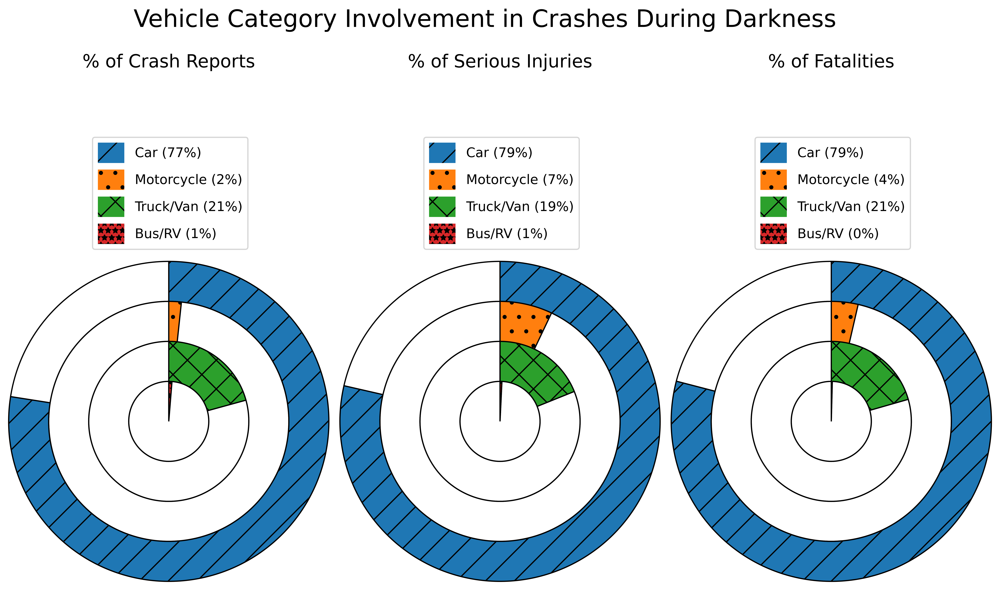

In [12]:
# modified example in following URL: https://stackoverflow.com/questions/49729748/create-a-circular-barplot-in-python

from matplotlib import cm
import matplotlib.patches as mpatches

# combine all vehicle types into general categories
analysis_2024['Car'] = analysis_2024['Pax'] + analysis_2024['SUV']
analysis_2024['Truck'] = analysis_2024['Van'] + analysis_2024['Medium Truck'] + analysis_2024['Heavy Truck']
dark = analysis_2024.loc[analysis_2024["Poor Lighting"]==1]

vehicle_columns = ['Car', 'Num_Motorcycle', 'Truck', 'Bus'] # to determine bar values in loop through each vehicle type data column

n = len(vehicle_columns) # number of rings
r = 1.45 # radius of whole pie
w = r / n  # width of each ring
m = 100 # max possible ring value, to represent percents with the typical visual convention (e.g., 75% = 3/4 of the pie)

labels = ['Car', 'Motorcycle', 'Truck/Van', 'Bus/RV']
colors = ['tab:blue','tab:orange','tab:green','tab:red']
patterns=['/','.','x','**']
textprops = {"alpha": 0} # hide labels in segments (alpha of 0 = transparent)

# establish patch color and hatching to accompany legend category and percent value label, which seems to throw off automatic patch formatting
car_patch = mpatches.Patch(hatch=patterns[0], facecolor=colors[0])
motorcycle_patch = mpatches.Patch(hatch=patterns[1], facecolor=colors[1])
truck_patch = mpatches.Patch(hatch=patterns[2], facecolor=colors[2])
bus_patch = mpatches.Patch(hatch=patterns[3], facecolor=colors[3])

dark_fatalities = []
dark_serious_injuries = []
dark_crashes = []

for i in vehicle_columns:
    # np.nan_to_num() is numpy equivalent of pandas .fillna(0) to avoid divide by zero errors in percentage calcs
    # note that boolean syntax references all rows where the vehicle type is greater than zero because the analysis database indicates a count of each vehicle type involved in each crash rather than a Y/N binary flag for vehicle type involvement
    perc_dark_fatalities = np.nan_to_num(dark.loc[dark[i]>0]['Fatality'].sum()/dark['Fatality'].sum()*100) # percent of total dark fatalities
    dark_fatalities.append(perc_dark_fatalities)
    perc_dark_serious_injuries = np.nan_to_num(dark.loc[dark[i]>0]['Incapacitating Injury'].sum()/dark['Incapacitating Injury'].sum()*100) # percent of total dark serious injuries 
    dark_serious_injuries.append(perc_dark_serious_injuries)    
    perc_dark_crashes = np.nan_to_num(dark.loc[dark[i]>0].shape[0]/dark.shape[0]*100) # integer-rounded percent of total dark crashes
    dark_crashes.append(perc_dark_crashes)

# create 1 row of 3 plots
fig, ax = plt.subplots(1,3, figsize=(14,10), dpi=700)
fig.suptitle('Vehicle Category Involvement in Crashes During Darkness', fontsize=20)

#create rings of donut chart
for i in range(n):
    innerring, _ = ax[2].pie([(m-dark_fatalities[i]), dark_fatalities[i]], radius=r-i*w, startangle=90, labels=["",labels[i]], textprops=textprops, colors=["none",colors[i]], hatch=["",patterns[i]]) # note that first color and hatch pattern define the "whitespace" fill color and hatching 
    plt.setp(innerring, width = w, edgecolor = "k")
    innerring, _ = ax[1].pie([(m-dark_serious_injuries[i]), dark_serious_injuries[i]], radius=r-i*w, startangle=90, labels=["",labels[i]], textprops=textprops, colors=["none",colors[i]], hatch=["",patterns[i]]) # note that first color and hatch pattern define the "whitespace" fill color and hatching 
    plt.setp(innerring, width = w, edgecolor = "k")
    innerring, _ = ax[0].pie([(m-dark_crashes[i]), dark_crashes[i]], radius=r-i*w, startangle=90, labels=["",labels[i]], textprops=textprops, colors=["none",colors[i]], hatch=["",patterns[i]]) # note that first color and hatch pattern define the "whitespace" fill color and hatching 
    plt.setp(innerring, width = w, edgecolor = "k")

ax[2].set_title("% of Fatalities", fontsize=15, pad=180)
ax[2].legend(labels=[f'{l} ({d:.0f}%)' for l, d in zip(labels, dark_fatalities)], handles = [car_patch, motorcycle_patch, truck_patch, bus_patch], fontsize=11, bbox_to_anchor=(0.2, 1.1), handleheight=2) # label = "<vehicle type category> (int(percent value)%)"; move legend outside of plot and increase patch size to view hatch pattern clearly
ax[1].set_title("% of Serious Injuries", fontsize=15, pad=180)
ax[1].legend(labels=[f'{l} ({d:.0f}%)' for l, d in zip(labels, dark_serious_injuries)], handles = [car_patch, motorcycle_patch, truck_patch, bus_patch], fontsize=11, bbox_to_anchor=(0.2, 1.1), handleheight=2) # label = "<vehicle type category> (int(percent value)%)"; move legend outside of plot and increase patch size to view hatch pattern clearly
ax[0].set_title("% of Crash Reports", fontsize=15, pad=180)
ax[0].legend(labels=[f'{l} ({d:.0f}%)' for l, d in zip(labels, dark_crashes)], handles = [car_patch, motorcycle_patch, truck_patch, bus_patch], fontsize=11, bbox_to_anchor=(0.2, 1.1), handleheight=2) # label = "<vehicle type category> (int(percent value)%)"; move legend outside of plot and increase patch size to view hatch pattern clearly

# Crash Reports by Year

<ipython-input-14-1883cfbbdabc>:10: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn')


Text(0, 0.5, 'Number of Crash Reports')

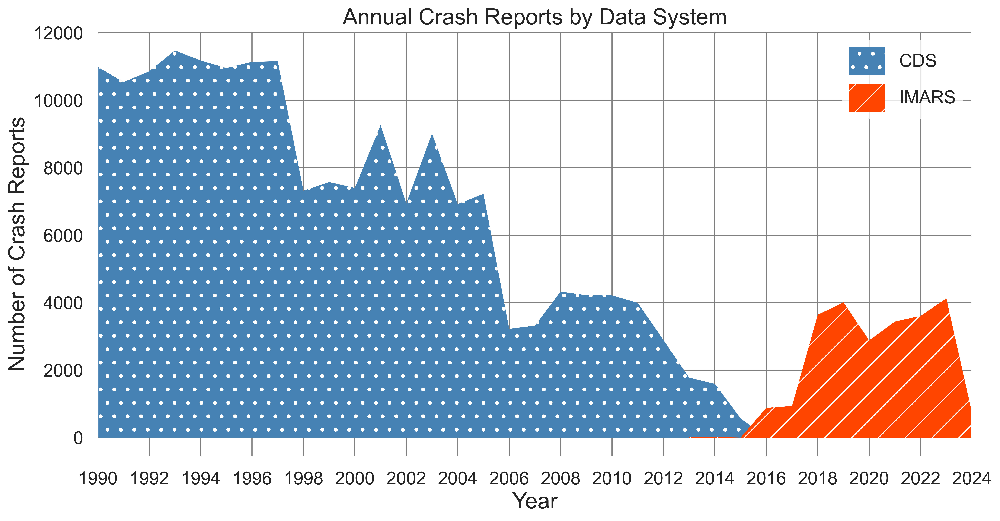

In [14]:
# set up dataframes for plotting
analysis_2024['Num_Crash'] = 1
goodyears = analysis_2024.loc[analysis_2024['YEAR'].isin(range(1988,2025))]
imars_all_year = goodyears.loc[goodyears['database']=="IMARS"].groupby('YEAR')
cds_all_year = goodyears.loc[goodyears['database']=="CDS"].groupby('YEAR')
imars_all_year_crashcounts = imars_all_year['Num_Crash'].sum()
cds_all_year_crashcounts = cds_all_year['Num_Crash'].sum()
    
# set up figure
plt.style.use('seaborn')
tick_spacing = 2 
sns.set(rc={'axes.facecolor':'1', 'figure.facecolor':'none', 'patch.linewidth': 0.0})
fig,ax = plt.subplots(1,1, figsize=(14, 7), dpi=700)
    
# plot data
ax.fill_between(cds_all_year_crashcounts.index, cds_all_year_crashcounts, label = 'CDS', facecolor = "steelblue", hatch = '.')
ax.fill_between(imars_all_year_crashcounts.index, imars_all_year_crashcounts, label = 'IMARS', facecolor = "orangered", hatch = '/')
    
# format plot
ax.set_title('Annual Crash Reports by Data System', fontsize=20)
legend = plt.legend(fontsize=16, handleheight=2, frameon=True, edgecolor='black')
plt.xlim([1990,2024])
ax.grid(visible=True, color = 'gray')
ax.xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
ax.tick_params(which='major', labelsize=16)
ax.set_xlabel("Year", fontsize=20)
ax.set_ylabel("Number of Crash Reports", fontsize=20)

# Urban/Rural

In [101]:
analysis_2024["Urban"].value_counts() # how to handle "suburban"?

Urban
urban       90270
rural       67020
suburban    43810
Name: count, dtype: int64

In [102]:
# re-assign suburban crashes as rural for the sake of the following analysis
analysis_2024['Urban'] = np.where(analysis_2024['Urban']=="suburban", "rural",analysis_2024['Urban'])
dark = analysis_2024.loc[analysis_2024["Poor Lighting"]==1]

# add outcome columns to set up analysis data tables
dark['Num_Crash'] = 1
dark['Darkness Attribute'] = 0 # initialize column with dummy data to replace with for loop
length = range(dark.shape[0])
for i in length: # in order of most to least common to speed up processing
    if dark['Dark_NotLit'].iloc[i]==1:
        dark['Darkness Attribute'].iloc[i] = "Dark - Not Lit"
    elif dark['Dark_Lit'].iloc[i]==1:
        dark['Darkness Attribute'].iloc[i] = "Dark - Lit"
    elif dark['Dusk'].iloc[i]==1:
        dark['Darkness Attribute'].iloc[i] = "Dusk"
    elif dark['Dawn'].iloc[i]==1:
        dark['Darkness Attribute'].iloc[i] = "Dawn"
    else:
        dark['Darkness Attribute'].iloc[i] = 'Dark - Unknown Lighting'

<ipython-input-102-8a9dcbdb9eb4>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dark['Num_Crash'] = 1
<ipython-input-102-8a9dcbdb9eb4>:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dark['Darkness Attribute'] = 0 # initialize column with dummy data to replace with for loop
<ipython-input-102-8a9dcbdb9eb4>:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.ht

<ipython-input-103-44952f16d318>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dark_slim["urb"] = np.where(dark_slim['Urban']=="urban",1,0)
<ipython-input-103-44952f16d318>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dark_slim["rur"] = np.where(dark_slim["Urban"]=="rural",1,0)
<ipython-input-103-44952f16d318>:12: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain ava

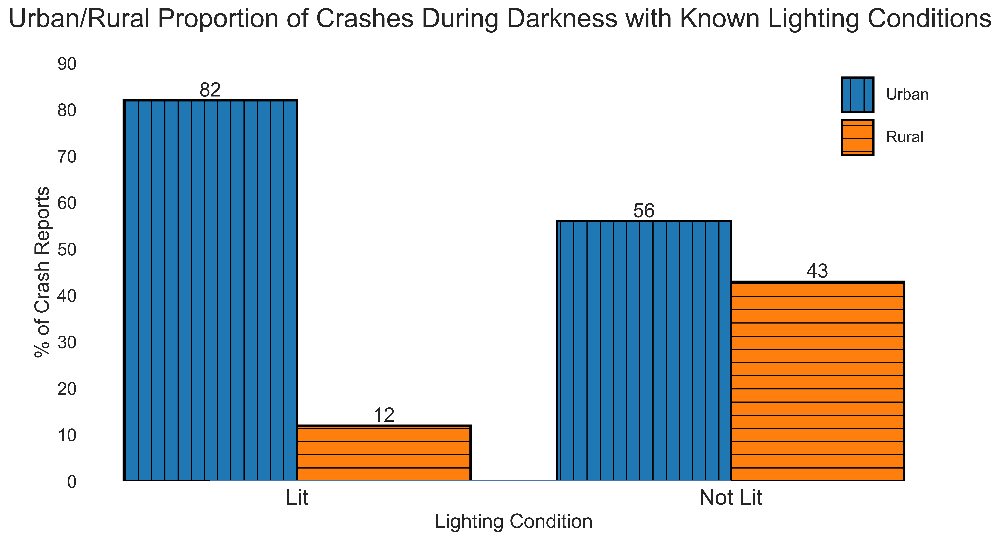

In [103]:
dark_slim = dark.loc[dark["Darkness Attribute"].isin(["Dark - Lit", "Dark - Not Lit"])]
dark_slim["urb"] = np.where(dark_slim['Urban']=="urban",1,0)
dark_slim["rur"] = np.where(dark_slim["Urban"]=="rural",1,0)
darklit = dark_slim.loc[dark_slim["Darkness Attribute"]=="Dark - Lit"]
darkunlit = dark_slim.loc[dark_slim["Darkness Attribute"]=="Dark - Not Lit"]
UrbanLitPerc = [round(darklit['urb'].sum()/darklit.shape[0]*100,0), round(darkunlit['urb'].sum()/darkunlit.shape[0]*100,0)]
RuralLitPerc = [round(darklit['rur'].sum()/darklit.shape[0]*100,0), round(darkunlit['rur'].sum()/darkunlit.shape[0]*100,0)]

from matplotlib.ticker import MaxNLocator
# plot prep
plt.style.use('seaborn')
fig, ax = plt.subplots(figsize=(14,7), dpi=700)
fig.suptitle('Urban/Rural Proportion of Crashes During Darkness with Known Lighting Conditions', fontsize=24)

# data
x1 = [0, 1.25]
x2 = [0.5, 1.75]
ax.bar(x1, UrbanLitPerc, width = 0.5, hatch = "|", color = 'tab:blue', edgecolor = "black", linewidth=2, label='Urban')
ax.bar(x2, RuralLitPerc, width = 0.5, hatch = "-", color = 'tab:orange', edgecolor = "black", linewidth=2, label='Rural')

# annotate plot with bar totals
rects = ax.patches
labels = [f"label{i}" for i in range(len(rects))]
for rect, label in zip(rects, labels):
    height = rect.get_height()
    label = '{:,}'.format(int(height))
    ax.text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

# format plot    
ax.set_ylim([0, 90])
ax.hlines(0, xmin = 0, xmax = 1.5, linewidth = 3)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel('Lighting Condition',fontsize = 18)
ax.set_ylabel("% of Crash Reports", fontsize = 18)
ax.tick_params(axis='x', which='major', labelsize=20)
ax.set_xticks([0.25, 1.5])
ax.set_xticklabels(['Lit','Not Lit'])
ax.tick_params(axis='y', which='major', labelsize=16)
ax.tick_params(axis='both', which='minor', labelsize=8)
ax.legend(fontsize='x-large', handleheight=3, handlelength = 2)
ax.set_facecolor('none')

In [106]:
# note that Lit and Unlit do not sum to 100% because not all crashes could be assigned urban/rural designation

# Prep Data Tables

In [75]:
# focus on darkness attributes re: poor visibility
dark = analysis_2024.loc[analysis_2024["Poor Lighting"]==1]
dark['Num_Crash'] = 1
dark.shape[0]

41167

## Poor Lighting First Harmful Event Type Table

In [80]:
dark['First_Harmful_Event_Type'].value_counts()

First_Harmful_Event_Type
Collision with person, MV or non-fixed object    17322
Collision with fixed object                      13184
Collision with animals                            5920
Non-collision                                     3004
Unknown                                           1671
Name: count, dtype: int64

In [89]:
dark_eventtype_outcomes = dark[['Num_Crash','Incapacitating Injury','Fatality','First_Harmful_Event_Type']] # subset for metrics Wayne is looking for
# outcomes for each first harmful event type, ordered by most to least common in crash report (reset index such that groupby data are now column in dataframe and can be manipulated as such)
dark_eventtype_agg = dark_eventtype_outcomes.groupby(['First_Harmful_Event_Type']).sum().sort_values(by=['Num_Crash'],ascending=False).reset_index()
    
dark_eventtype_rates = dark_eventtype_agg[["First_Harmful_Event_Type", "Num_Crash"]]
dark_eventtype_rates['Crash "Rate" (percent of total crashes)'] = round(dark_eventtype_agg['Num_Crash']/dark_eventtype_outcomes.shape[0]*100,1).astype(str) + "%" # convert percent value to string in order to append percent symbol
dark_eventtype_rates['Average Serious Injury "Rate"'] = round(dark_eventtype_agg['Num_Crash']/dark_eventtype_agg['Incapacitating Injury'],0).astype(int) # compute number of crashes per serious injury
dark_eventtype_rates['Average Serious Injury "Rate"'] = dark_eventtype_rates['Average Serious Injury "Rate"'].astype(str) # convert to string to prepare for text prepend and append in table cell value
dark_eventtype_rates['Average Serious Injury "Rate"'] = "1 every " + dark_eventtype_rates['Average Serious Injury "Rate"'] + " crashes" # "1 serious injury for every X crashes"
dark_eventtype_rates['Average Fatality "Rate"'] = round(dark_eventtype_agg['Num_Crash']/dark_eventtype_agg['Fatality'],0).astype(int) # compute number of crashes per fatality
dark_eventtype_rates['Average Fatality "Rate"'] = dark_eventtype_rates['Average Fatality "Rate"'].astype(str) # convert to string to prepare for text prepend and append in table cell value
dark_eventtype_rates['Average Fatality "Rate"'] = "1 every " + dark_eventtype_rates['Average Fatality "Rate"'] + " crashes" # "1 fatality for every X crashes"

    
# format data table for display
dark_eventtype_rates = dark_eventtype_rates.rename(columns={'First_Harmful_Event_Type':'First Harmful Event Type'})
dark_eventtype_rates = dark_eventtype_rates.drop(columns={'Num_Crash'})
dark_eventtype_rates

<ipython-input-89-988f334f0da3>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dark_eventtype_rates['Crash "Rate" (percent of total crashes)'] = round(dark_eventtype_agg['Num_Crash']/dark_eventtype_outcomes.shape[0]*100,1).astype(str) + "%" # convert percent value to string in order to append percent symbol


,First Harmful Event Type,"Crash ""Rate"" (percent of total crashes)","Average Serious Injury ""Rate""","Average Fatality ""Rate"""
0,"Collision with person, MV or non-fixed object",42.1%,1 every 24 crashes,1 every 97 crashes
1,Collision with fixed object,32.0%,1 every 13 crashes,1 every 52 crashes
2,Collision with animals,14.4%,1 every 211 crashes,1 every 1973 crashes
3,Non-collision,7.3%,1 every 17 crashes,1 every 68 crashes
4,Unknown,4.1%,1 every 24 crashes,1 every 73 crashes


## First Harmful Event Type Table (All Crashes for Context)

In [91]:
analysis_2024['Num_Crash'] = 1
eventtype_outcomes = analysis_2024[['Num_Crash','Incapacitating Injury','Fatality','First_Harmful_Event_Type']] # subset for metrics Wayne is looking for
# outcomes for each first harmful event type, ordered by most to least common in crash report (reset index such that groupby data are now column in dataframe and can be manipulated as such)
eventtype_agg = eventtype_outcomes.groupby(['First_Harmful_Event_Type']).sum().sort_values(by=['Num_Crash'],ascending=False).reset_index()
    
eventtype_rates = eventtype_agg[["First_Harmful_Event_Type", "Num_Crash"]]
eventtype_rates['Crash "Rate" (percent of total crashes)'] = round(eventtype_agg['Num_Crash']/eventtype_outcomes.shape[0]*100,1).astype(str) + "%" # convert percent value to string in order to append percent symbol
eventtype_rates['Average Serious Injury "Rate"'] = round(eventtype_agg['Num_Crash']/eventtype_agg['Incapacitating Injury'],0).astype(int) # compute number of crashes per serious injury
eventtype_rates['Average Serious Injury "Rate"'] = eventtype_rates['Average Serious Injury "Rate"'].astype(str) # convert to string to prepare for text prepend and append in table cell value
eventtype_rates['Average Serious Injury "Rate"'] = "1 every " + eventtype_rates['Average Serious Injury "Rate"'] + " crashes" # "1 serious injury for every X crashes"
eventtype_rates['Average Fatality "Rate"'] = round(eventtype_agg['Num_Crash']/eventtype_agg['Fatality'],0).astype(int) # compute number of crashes per fatality
eventtype_rates['Average Fatality "Rate"'] = eventtype_rates['Average Fatality "Rate"'].astype(str) # convert to string to prepare for text prepend and append in table cell value
eventtype_rates['Average Fatality "Rate"'] = "1 every " + eventtype_rates['Average Fatality "Rate"'] + " crashes" # "1 fatality for every X crashes"

    
# format data table for display
eventtype_rates = eventtype_rates.rename(columns={'First_Harmful_Event_Type':'First Harmful Event Type'})
eventtype_rates = eventtype_rates.drop(columns={'Num_Crash'})
eventtype_rates

<ipython-input-91-845cbde62886>:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  eventtype_rates['Crash "Rate" (percent of total crashes)'] = round(eventtype_agg['Num_Crash']/eventtype_outcomes.shape[0]*100,1).astype(str) + "%" # convert percent value to string in order to append percent symbol


,First Harmful Event Type,"Crash ""Rate"" (percent of total crashes)","Average Serious Injury ""Rate""","Average Fatality ""Rate"""
0,"Collision with person, MV or non-fixed object",54.6%,1 every 33 crashes,1 every 232 crashes
1,Collision with fixed object,23.5%,1 every 17 crashes,1 every 82 crashes
2,Collision with animals,9.2%,1 every 123 crashes,1 every 915 crashes
3,Non-collision,7.5%,1 every 12 crashes,1 every 91 crashes
4,Unknown,4.9%,1 every 22 crashes,1 every 108 crashes


## Poor Lighting Attribute Outcomes - Rates

In [94]:
dark = analysis_2024.loc[analysis_2024['Poor Lighting']==1]
dark['Darkness Attribute'] = 0 # initialize column with dummy data to replace with for loop
length = range(dark.shape[0])
for i in length: # in order of most to least common to speed up processing
    if dark['Dark_NotLit'].iloc[i]==1:
        dark['Darkness Attribute'].iloc[i] = "Dark - Not Lit"
    elif dark['Dark_Lit'].iloc[i]==1:
        dark['Darkness Attribute'].iloc[i] = "Dark - Lit"
    elif dark['Dusk'].iloc[i]==1:
        dark['Darkness Attribute'].iloc[i] = "Dusk"
    elif dark['Dawn'].iloc[i]==1:
        dark['Darkness Attribute'].iloc[i] = "Dawn"
    else:
        dark['Darkness Attribute'].iloc[i] = 'Dark - Unknown Lighting'
dark_summary = dark[['Num_Crash','Incapacitating Injury','Fatality','Darkness Attribute']]
# outcomes for each darkness attribute, ordered by most to least common in crash report (reset index such that groupby data are now column in dataframe and can be manipulated as such)
dark_summary_agg = dark_summary.groupby(['Darkness Attribute']).sum().sort_values(by=['Num_Crash'],ascending=False).reset_index()
    
dark_summary_rates = dark_summary_agg[["Darkness Attribute", "Num_Crash"]]
dark_summary_rates['Crash "Rate" (percent of total crashes)'] = round(dark_summary_agg['Num_Crash']/dark_summary.shape[0]*100,1).astype(str) + "%" # convert percent value to string in order to append percent symbol
dark_summary_rates['Average Serious Injury "Rate"'] = np.nan_to_num(round(dark_summary_agg['Num_Crash']/dark_summary_agg['Incapacitating Injury'],0)).astype(int) # compute number of crashes per serious injury
dark_summary_rates['Average Serious Injury "Rate"'] = dark_summary_rates['Average Serious Injury "Rate"'].astype(str) # convert value to string for text prepend and append in table cell
dark_summary_rates['Average Serious Injury "Rate"'] = "1 every " + dark_summary_rates['Average Serious Injury "Rate"'] + " crashes" # "1 serious injury for every X crashes"
dark_summary_rates['Average Fatality "Rate"'] = np.nan_to_num(round(dark_summary_agg['Num_Crash']/dark_summary_agg['Fatality'],0)).astype(int) # compute number of crashes per fatality
dark_summary_rates['Average Fatality "Rate"'] = dark_summary_rates['Average Fatality "Rate"'].astype(str) # convert value to string for text prepend and append in table cell
dark_summary_rates['Average Fatality "Rate"'] = "1 every " + dark_summary_rates['Average Fatality "Rate"'] + " crashes"  # "1 fatality for every X crashes"
    
# format data table for display
dark_summary_rates = dark_summary_rates.drop(columns={'Num_Crash'})
dark_summary_rates

<ipython-input-94-f5a772d9b803>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dark['Darkness Attribute'] = 0 # initialize column with dummy data to replace with for loop
<ipython-input-94-f5a772d9b803>:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dark['Darkness Attribute'].iloc[i] = "Dusk"
<ipython-input-94-f5a772d9b803>:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d

,Darkness Attribute,"Crash ""Rate"" (percent of total crashes)","Average Serious Injury ""Rate""","Average Fatality ""Rate"""
0,Dark - Not Lit,41.5%,1 every 21 crashes,1 every 74 crashes
1,Dark - Unknown Lighting,29.7%,1 every 17 crashes,1 every 67 crashes
2,Dark - Lit,16.0%,1 every 29 crashes,1 every 134 crashes
3,Dusk,7.9%,1 every 27 crashes,1 every 162 crashes
4,Dawn,5.0%,1 every 30 crashes,1 every 109 crashes


## General Light Attribute Outcomes - Rates

In [95]:
analysis_2024['Lighting Category'] = 0 # initialize column with dummy data to replace with for loop

# assign general lighting categories
length = range(analysis_2024.shape[0])
for i in length: # in order of most to least common to speed up processing
    if analysis_2024['Daylight'].iloc[i]==1:
        analysis_2024['Lighting Category'].iloc[i] = "Daylight"
    elif analysis_2024['UnknownBlankNullLit'].iloc[i]==1:
        analysis_2024['Lighting Category'].iloc[i] = "Unknown"
    elif analysis_2024['Poor Lighting'].iloc[i]==1:
        analysis_2024['Lighting Category'].iloc[i] = "Dark"
        
analysis_2024['Lighting Category'].value_counts() # 87 counts of "0" from IMARS crashes in which lighting was described as "other" and could therefore not fit into the other three broad categories

<ipython-input-95-ff1c37b2d222>:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  analysis_2024['Lighting Category'].iloc[i] = "Daylight"


Lighting Category
Daylight    108608
Unknown      68731
Dark         41167
0               87
Name: count, dtype: int64

In [96]:
df_clean = analysis_2024.loc[analysis_2024['Lighting Category']!=0] # remove 87 "other" lighting crashes from IMARS
df_summary = df_clean[['Num_Crash','Incapacitating Injury','Fatality','Lighting Category']]
# outcomes for each lighting category, ordered by most to least common in crash report (reset index such that groupby data are now column in dataframe and can be manipulated as such)
df_summary_agg = df_summary.groupby(['Lighting Category']).sum().sort_values(by=['Num_Crash'],ascending=False).reset_index()
    
df_summary_rates = df_summary_agg[["Lighting Category", "Num_Crash"]]
df_summary_rates['Crash "Rate" (percent of total crashes)'] = round(df_summary_agg['Num_Crash']/df_summary.shape[0]*100,1).astype(str) + "%" # convert rounded percent value to string in order to append percent symbol
df_summary_rates['Average Serious Injury "Rate"'] = np.nan_to_num(round(df_summary_agg['Num_Crash']/df_summary_agg['Incapacitating Injury'],0)).astype(int) # compute number of crashes per serious injury
df_summary_rates['Average Serious Injury "Rate"'] = df_summary_rates['Average Serious Injury "Rate"'].astype(str) # convert to string required for text prepend and append
df_summary_rates['Average Serious Injury "Rate"'] = "1 every " + df_summary_rates['Average Serious Injury "Rate"'] + " crashes" # "1 serious injury for every X crashes"
df_summary_rates['Average Fatality "Rate"'] = np.nan_to_num(round(df_summary_agg['Num_Crash']/df_summary_agg['Fatality'],0)).astype(int) # compute number of crashes per fatality
df_summary_rates['Average Fatality "Rate"'] = df_summary_rates['Average Fatality "Rate"'].astype(str) # convert to string required for text prepend and append
df_summary_rates['Average Fatality "Rate"'] = "1 every " + df_summary_rates['Average Fatality "Rate"'] + " crashes" # "1 fatality for every X crashes"
    
# format data table for display
df_summary_rates = df_summary_rates.drop(columns={'Num_Crash'})
df_summary_rates

<ipython-input-96-01fd38954e42>:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_summary_rates['Crash "Rate" (percent of total crashes)'] = round(df_summary_agg['Num_Crash']/df_summary.shape[0]*100,1).astype(str) + "%" # convert rounded percent value to string in order to append percent symbol


,Lighting Category,"Crash ""Rate"" (percent of total crashes)","Average Serious Injury ""Rate""","Average Fatality ""Rate"""
0,Daylight,49.7%,1 every 28 crashes,1 every 214 crashes
1,Unknown,31.5%,1 every 24 crashes,1 every 156 crashes
2,Dark,18.8%,1 every 21 crashes,1 every 82 crashes
